# 10 - Final submission and transparent comparisons
Write the configured model-driven MILP policy and compare July model projections with feasible baselines. Historical observed-outcome evidence is reported separately; deployment is not claimed to be the development-validation winner.


## Load data + constants

In [1]:
import sys, math, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.common import ROOT, TABLES, FIGS, load_clean, load_processed
from src.policy import ACTIONS, COMMERCIAL, build_baseline_policies, assert_feasible
pd.set_option("display.width", 200)
FINAL = ROOT / "outputs" / "final"; FINAL.mkdir(exist_ok=True)
vals = pd.read_csv(TABLES / "july_customer_action_values.csv")
pol = pd.read_csv(TABLES / "selected_policy_detailed.csv")
hold_ids = set(pd.read_csv(TABLES / "measurement_holdout.csv").customer_id)
ps = load_clean(["policy_scoring_population"])["policy_scoring_population"]
hist = load_processed("historical_feature_outcome")
BUDGET, MAX_OFFER_SHARE, MAX_PCT20_SHARE, HOLDOUT_SHARE = 62_000, 0.60, 0.15, 0.05
N = len(ps); MAX_OFFERS = math.floor(MAX_OFFER_SHARE * N)
V = vals.set_index(["customer_id", "action"])
COLORS = dict(zip(ACTIONS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

## A. Exact final submission + checks (fail loudly)

In [2]:
SUB_COLS = ["customer_id", "recommended_action", "estimated_incremental_ncm", "estimated_promo_cost"]
sub = pol[SUB_COLS].sort_values("customer_id").reset_index(drop=True)
sub[["estimated_incremental_ncm", "estimated_promo_cost"]] = sub[["estimated_incremental_ncm", "estimated_promo_cost"]].round(4)
n_off = sub.recommended_action.ne("NO_OFFER").sum(); n20 = sub.recommended_action.eq("PCT_20").sum()
ref = V.loc[list(zip(sub.customer_id, sub.recommended_action)), ["estimated_incremental_ncm", "estimated_promo_cost"]].to_numpy()
checks = {
    "exact columns / order": list(sub.columns) == SUB_COLS,
    "every scoring customer exactly once": len(sub) == N and sub.customer_id.is_unique and set(sub.customer_id) == set(ps.customer_id),
    "valid, non-missing actions": sub.recommended_action.isin(ACTIONS).all(),
    "finite incremental NCM and promo cost": np.isfinite(sub[["estimated_incremental_ncm", "estimated_promo_cost"]].to_numpy()).all(),
    "promo cost >= 0": (sub.estimated_promo_cost >= 0).all(),
    "expected promo spend <= $62,000": sub.estimated_promo_cost.sum() <= BUDGET,
    "offered share <= 60%": n_off <= MAX_OFFERS,
    "PCT_20 share among offered <= 15%": n20 <= MAX_PCT20_SHARE * n_off + 1e-9,
    "all reserved holdout customers NO_OFFER": sub[sub.customer_id.isin(hold_ids)].recommended_action.eq("NO_OFFER").all(),
    "reserved holdout >= 5%": len(hold_ids) >= math.ceil(HOLDOUT_SHARE * N),
    "values match Step 09 selected rows": np.allclose(sub[["estimated_incremental_ncm", "estimated_promo_cost"]].to_numpy(), ref, atol=1e-4)}
print(pd.Series(checks).to_string()); assert all(checks.values()), checks
sub.to_csv(ROOT / "policy_submission.csv", index=False)
sub.to_csv(FINAL / "policy_submission.csv", index=False)
print(sub.shape, list(sub.columns))

exact columns / order                      True
every scoring customer exactly once        True
valid, non-missing actions                 True
finite incremental NCM and promo cost      True
promo cost >= 0                            True
expected promo spend <= $62,000            True
offered share <= 60%                       True
PCT_20 share among offered <= 15%          True
all reserved holdout customers NO_OFFER    True
reserved holdout >= 5%                     True
values match Step 09 selected rows         True
(2776, 4) ['customer_id', 'recommended_action', 'estimated_incremental_ncm', 'estimated_promo_cost']


## B. Feasible baseline policies
The three required baselines use the same holdout, budget, offer cap and PCT_20 cap.
Add RANDOM_FREE_SHIP to assess whether personalized action selection improves on a simple feasible policy.
Historical mix shares come only from historical business-rule assignments; backtests estimate the mix from their training periods.


In [3]:
br = hist.loc[hist.assignment_source == "business_rule", "offer_type"]
mix = br[br != "NO_OFFER"].value_counts(normalize=True).reindex(COMMERCIAL, fill_value=0)
baseline_rows = build_baseline_policies(vals, historical_mix=mix.to_dict(), budget=BUDGET,
                                       max_offer_share=MAX_OFFER_SHARE, max_pct20_share=MAX_PCT20_SHARE,
                                       holdout_ids=hold_ids, seed=42)
policies = {name: p.set_index("customer_id").recommended_action for name, p in baseline_rows.items()}
policies["SELECTED_POLICY"] = pol.set_index("customer_id").recommended_action
mix_metadata = {"source": "historical business_rule commercial assignments",
                "training_campaigns": sorted(hist.campaign_id.unique().tolist()),
                "commercial_offer_shares": mix.to_dict(),
                "july_baseline_only": True,
                "backtest_rule": "re-estimate these shares on each historical training fold only"}
(TABLES / "historical_mix_metadata.json").write_text(json.dumps(mix_metadata, indent=2))
print("historical business-rule commercial mix:", mix.round(3).to_dict())


historical business-rule commercial mix: {'PCT_10': 0.598, 'PCT_20': 0.131, 'FREE_SHIP': 0.271}


## Model-projection comparison (not independent validation)
The MILP maximizes these same model forecasts under the stated constraints. Solver optimality establishes the best assignment for those inputs within numerical tolerances; it does not validate the predictions or establish actual July profit. Historical outcome-based evaluation is separate from these projections.


In [4]:
def evaluate(name, p):
    s = V.loc[list(zip(p.index, p.values))]
    n_o = int((p != "NO_OFFER").sum()); n_20 = int((p == "PCT_20").sum()); sp = s.estimated_promo_cost.sum(); inc = s.estimated_incremental_ncm.sum()
    return {"policy": name, "evaluation_basis": "model_projection_not_independent_validation", "customers": len(p), **{f"n_{a}": int((p == a).sum()) for a in ACTIONS}, "offer_share": n_o / len(p),
            "pct20_share_among_offered": n_20 / n_o if n_o else 0.0, "expected_promo_spend": sp, "total_expected_ncm": s.predicted_ncm.sum(),
            "total_expected_incremental_ncm": inc, "incremental_ncm_per_customer": inc / len(p),
            "incremental_ncm_per_promo_dollar": inc / sp if sp > 0 else np.nan,
            "holdout_all_no_offer": bool((p[list(hold_ids)] == "NO_OFFER").all()),
            "within_all_constraints": sp <= BUDGET and n_o <= MAX_OFFERS and n_20 <= MAX_PCT20_SHARE * n_o + 1e-9}
cmp = pd.DataFrame([evaluate(k, v) for k, v in policies.items()])
assert cmp.within_all_constraints.all() and cmp.holdout_all_no_offer.all()
cmp.to_csv(TABLES / "baseline_policy_comparison.csv", index=False)
pd.DataFrame(policies).rename_axis("customer_id").reset_index().to_csv(TABLES / "baseline_policy_assignments.csv", index=False)
cmp.set_index("policy").T.round(3)

policy,ALL_NO_OFFER,PROPENSITY_PCT10,HISTORICAL_MIX,RANDOM_FREE_SHIP,SELECTED_POLICY
evaluation_basis,model_projection_not_independent_validation,model_projection_not_independent_validation,model_projection_not_independent_validation,model_projection_not_independent_validation,model_projection_not_independent_validation
customers,2776,2776,2776,2776,2776
n_NO_OFFER,2776,1111,1111,1111,1111
n_PCT_10,0,1665,996,0,0
n_PCT_20,0,0,218,0,0
n_FREE_SHIP,0,0,451,1665,1665
offer_share,0.0,0.599784,0.599784,0.599784,0.599784
pct20_share_among_offered,0.0,0.0,0.130931,0.0,0.0
expected_promo_spend,0.0,7585.320187,6209.267112,167.443442,167.443442
total_expected_ncm,45028.504082,42899.441512,43300.311837,47027.878879,47530.287458


## Reporting tables

In [5]:
fin = pol.merge(vals.pivot(index="customer_id", columns="action", values="predicted_ncm").add_prefix("predicted_ncm_"), on="customer_id")
fin = fin.merge(vals.pivot(index="customer_id", columns="action", values="estimated_incremental_ncm").add_prefix("incremental_ncm_"), on="customer_id")
fin = fin.merge(vals.pivot(index="customer_id", columns="action", values="estimated_promo_cost").add_prefix("promo_cost_"), on="customer_id")
jf = load_processed("july_features")
fin = fin.merge(jf[["customer_id", "customer_tier", "is_member", "region", "customer_tenure_days", "observed_prior_order_count", "observed_orders_30d", "observed_orders_90d", "complete_orders_30d", "complete_orders_90d", "orders_30d_coverage_status", "orders_90d_coverage_status", "sessions_30d"]], on="customer_id")
fin.to_csv(TABLES / "customer_policy_audit.csv", index=False)
act = pol.groupby("recommended_action").agg(customers=("customer_id", "size"), expected_incremental_ncm=("estimated_incremental_ncm", "sum"),
                                            mean_incremental_ncm=("estimated_incremental_ncm", "mean"), expected_promo_spend=("estimated_promo_cost", "sum"),
                                            mean_purchase_probability=("predicted_purchase_probability", "mean"),
                                            holdout_customers=("measurement_holdout", "sum")).reindex(ACTIONS, fill_value=0)
act.insert(1, "share", act.customers / N)
act.rename_axis("action").to_csv(TABLES / "policy_action_summary.csv")
o = cmp.set_index("policy").loc["SELECTED_POLICY"]
fps = pd.DataFrame([("customers scored", N, ""), ("total expected incremental NCM ($)", round(o.total_expected_incremental_ncm, 2), ""),
                    ("total expected NCM ($)", round(o.total_expected_ncm, 2), ""), ("expected promo spend ($)", round(o.expected_promo_spend, 2), f"<= {BUDGET}"),
                    ("offer share", round(o.offer_share, 4), f"<= {MAX_OFFER_SHARE}"), ("PCT_20 share among offered", round(o.pct20_share_among_offered, 4), f"<= {MAX_PCT20_SHARE}"),
                    ("measurement holdout share", round(len(hold_ids) / N, 4), f">= {HOLDOUT_SHARE}"),
                    ("incremental NCM vs PROPENSITY_PCT10 ($)", round(o.total_expected_incremental_ncm - cmp.set_index("policy").loc["PROPENSITY_PCT10", "total_expected_incremental_ncm"], 2), ""),
                    ("incremental NCM vs HISTORICAL_MIX ($)", round(o.total_expected_incremental_ncm - cmp.set_index("policy").loc["HISTORICAL_MIX", "total_expected_incremental_ncm"], 2), "")],
                   columns=["metric", "value", "limit"])
fps["evaluation_basis"] = "model_projection_not_independent_validation"
fps.to_csv(TABLES / "final_policy_summary.csv", index=False)
act.round(3)

,customers,share,expected_incremental_ncm,mean_incremental_ncm,expected_promo_spend,mean_purchase_probability,holdout_customers
recommended_action,,,,,,,
NO_OFFER,1111,0.4,0.000,0.000,0.000,0.082,139
PCT_10,0,0.0,0.000,0.000,0.000,0.000,0
PCT_20,0,0.0,0.000,0.000,0.000,0.000,0
FREE_SHIP,1665,0.6,2501.783,1.503,167.443,0.163,0


## Figures

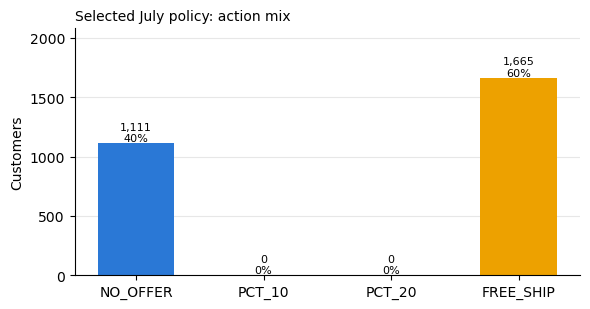

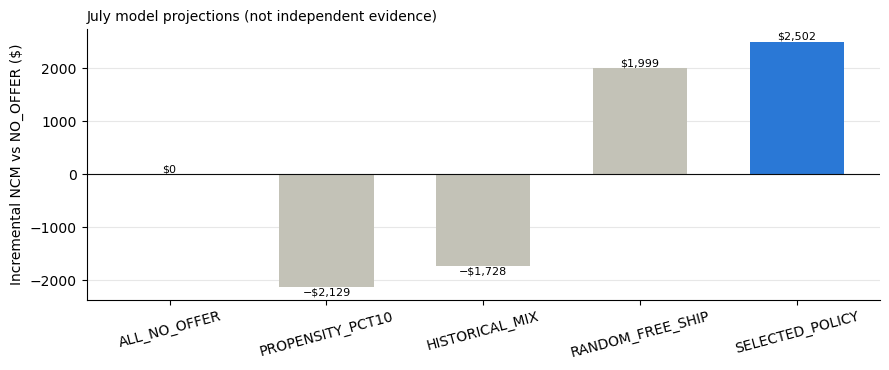

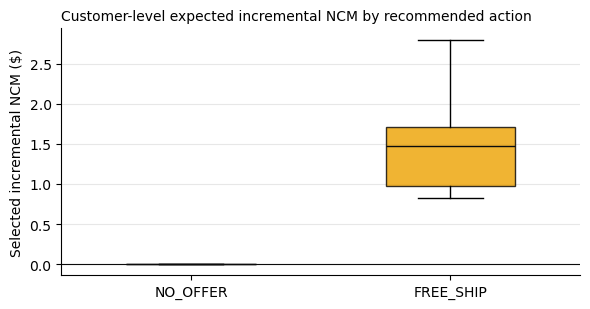

In [6]:
def style(a):
    a.spines[["top", "right"]].set_visible(False); a.grid(axis="y", alpha=0.3); a.set_axisbelow(True)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(ACTIONS, act.customers, color=[COLORS[a] for a in ACTIONS], width=0.6)
for i, (c, s) in enumerate(zip(act.customers, act.share)):
    ax.text(i, c, f"{c:,}\n{s:.0%}", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Customers"); ax.set_title("Selected July policy: action mix", loc="left", fontsize=10); ax.set_ylim(0, act.customers.max() * 1.25); style(ax)
fig.tight_layout(); fig.savefig(FIGS / "10_optimized_action_mix.png", dpi=130, bbox_inches="tight"); plt.show()
fig, ax = plt.subplots(figsize=(9, 3.8))
# Each policy appears once in the comparison.
plot_cmp = cmp
ax.bar(plot_cmp.policy, plot_cmp.total_expected_incremental_ncm, color=["#2a78d6" if p == "SELECTED_POLICY" else "#c3c2b7" for p in plot_cmp.policy], width=0.6)
ax.axhline(0, color="#0b0b0b", lw=0.8)
for i, v in enumerate(plot_cmp.total_expected_incremental_ncm):
    ax.text(i, v, f"{'−' if v < 0 else ''}${abs(v):,.0f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
ax.set_ylabel("Incremental NCM vs NO_OFFER ($)"); ax.set_title("July model projections (not independent evidence)", loc="left", fontsize=10); ax.tick_params(axis="x", labelrotation=15); style(ax)
fig.tight_layout(); fig.savefig(FIGS / "10_baseline_comparison.png", dpi=130, bbox_inches="tight"); plt.show()
fig, ax = plt.subplots(figsize=(6, 3.2))
data = [pol.loc[pol.recommended_action == a, "estimated_incremental_ncm"] for a in ACTIONS if (pol.recommended_action == a).any()]
labs = [a for a in ACTIONS if (pol.recommended_action == a).any()]
bp = ax.boxplot(data, tick_labels=labs, patch_artist=True, showfliers=False, widths=0.5, medianprops={"color": "#0b0b0b"})
for patch, a in zip(bp["boxes"], labs):
    patch.set_facecolor(COLORS[a]); patch.set_alpha(0.8)
ax.axhline(0, color="#0b0b0b", lw=0.8); ax.set_ylabel("Selected incremental NCM ($)")
ax.set_title("Customer-level expected incremental NCM by recommended action", loc="left", fontsize=10); style(ax)
fig.tight_layout(); fig.savefig(FIGS / "10_selected_incremental_by_action.png", dpi=130, bbox_inches="tight"); plt.show()

## Held-out evidence and July measurement
The table below uses observed historical outcomes, unlike the July projection chart.
For July, compare ALL policy-arm customers (including policy-selected NO_OFFER) with the reserved randomized controls.


In [7]:
evidence_path = TABLES / "heldout_policy_comparison.csv"
if evidence_path.exists():
    display(pd.read_csv(evidence_path))
else:
    print("Held-out policy evidence not generated yet. Run the evaluation step before making profit claims.")
print("July analysis plan: outputs/tables/measurement_design.json")
print("Randomized arms: outputs/tables/measurement_assignment.csv")


July analysis plan: outputs/tables/measurement_design.json
Randomized arms: outputs/tables/measurement_assignment.csv


,split,policy,n,dr_ncm_per_customer,dr_incremental_ncm_per_customer,ci_low,ci_high,hajek_incremental_ncm_per_customer,uniform_propensity_dr_incremental_ncm,estimated_promo_spend,dr_promo_spend,dr_promo_spend_ci_low,dr_promo_spend_ci_high,offered_share,matched_rows,effective_sample_size,budget,propensity_source,interval_method,inner_validation_campaign,fold_parameters,allocation_algorithm,purchase_baseline_config,purchase_validation_campaigns,purchase_baseline_selection,selected_for_july,selected_by_development
0,CP07,ORIGINAL_TLEARNER,1060,13.809965,3.971406,-2.233164,9.682505,3.075549,3.609214,989.798175,400.373437,-75.298357,885.353529,0.6,251,250.767341,23674.351585,empirical_within_campaign_unconditional_random...,customer_cluster_bootstrap_reestimating_campai...,CP06,"{""learning_rate"": 0.03, ""max_depth"": 1, ""n_est...",scipy_highs_milp,"{""C"": 0.01, ""calibration"": ""none"", ""mode"": ""raw""}",[],user-fixed original logistic; earlier-campaign...,False,False
1,CP07,ACTION_MEAN,1060,15.409859,5.571300,-2.097807,13.623382,5.945976,5.449961,60.396732,70.701553,-0.601925,161.732541,0.6,271,270.922319,23674.351585,empirical_within_campaign_unconditional_random...,customer_cluster_bootstrap_reestimating_campai...,CP06,"{""learning_rate"": 0.03, ""max_depth"": 1, ""n_est...",scipy_highs_milp,"{""C"": 0.01, ""calibration"": ""none"", ""mode"": ""raw""}",[],user-fixed original logistic; earlier-campaign...,False,False
2,CP07,HURDLE_XGB_HALF,1060,18.727320,8.888760,0.252821,18.029904,8.916941,8.703118,60.396732,95.328329,19.984031,195.988428,0.6,258,257.927432,23674.351585,empirical_within_campaign_unconditional_random...,customer_cluster_bootstrap_reestimating_campai...,CP06,"{""learning_rate"": 0.03, ""max_depth"": 1, ""n_est...",scipy_highs_milp,"{""C"": 0.01, ""calibration"": ""none"", ""mode"": ""raw""}",[],user-fixed original logistic; earlier-campaign...,True,False
3,CP07,ALL_NO_OFFER,1060,9.838560,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,257,257.000000,23674.351585,empirical_within_campaign_unconditional_random...,customer_cluster_bootstrap_reestimating_campai...,NaN,NaN,feasible_baseline_rule,"{""C"": 0.01, ""calibration"": ""none"", ""mode"": ""raw""}",[],user-fixed original logistic; earlier-campaign...,False,False
4,CP07,PROPENSITY_PCT10,1060,13.489538,3.650978,-2.492067,9.759834,3.112313,3.427171,3430.816452,3402.305225,2024.827670,4902.494946,0.6,258,256.907927,23674.351585,empirical_within_campaign_unconditional_random...,customer_cluster_bootstrap_reestimating_campai...,NaN,NaN,feasible_baseline_rule,"{""C"": 0.01, ""calibration"": ""none"", ""mode"": ""raw""}",[],user-fixed original logistic; earlier-campaign...,False,False
5,CP07,HISTORICAL_MIX,1060,14.498414,4.659854,-0.483924,9.758685,3.030309,4.456535,2443.568935,3361.580238,1670.480984,5304.148274,0.6,237,235.932607,23674.351585,empirical_within_campaign_unconditional_random...,customer_cluster_bootstrap_reestimating_campai...,NaN,NaN,feasible_baseline_rule,"{""C"": 0.01, ""calibration"": ""none"", ""mode"": ""raw""}",[],user-fixed original logistic; earlier-campaign...,False,False
6,CP07,RANDOM_FREE_SHIP,1060,22.579989,12.741429,3.589919,22.663654,12.231746,12.569439,60.396732,71.836830,0.316796,157.012688,0.6,246,245.932735,23674.351585,empirical_within_campaign_unconditional_random...,customer_cluster_bootstrap_reestimating_campai...,NaN,NaN,feasible_baseline_rule,"{""C"": 0.01, ""calibration"": ""none"", ""mode"": ""raw""}",[],user-fixed original logistic; earlier-campaign...,False,True


## Output paths

In [8]:
for p in ["policy_submission.csv", "outputs/final/policy_submission.csv", "outputs/tables/baseline_policy_comparison.csv",
          "outputs/tables/baseline_policy_assignments.csv", "outputs/tables/final_policy_summary.csv", "outputs/tables/policy_action_summary.csv",
          "outputs/tables/customer_policy_audit.csv", "outputs/figures/10_optimized_action_mix.png", "outputs/figures/10_baseline_comparison.png",
          "outputs/figures/10_selected_incremental_by_action.png"]:
    assert (ROOT / p).exists(), p
    print(" ", p)

  policy_submission.csv
  outputs/final/policy_submission.csv
  outputs/tables/baseline_policy_comparison.csv
  outputs/tables/baseline_policy_assignments.csv
  outputs/tables/final_policy_summary.csv
  outputs/tables/policy_action_summary.csv
  outputs/tables/customer_policy_audit.csv
  outputs/figures/10_optimized_action_mix.png
  outputs/figures/10_baseline_comparison.png
  outputs/figures/10_selected_incremental_by_action.png
